<div style="background: linear-gradient(90deg, #0b3c5d 0%, #1d6fa3 60%, #5fb3d9 100%); padding: 28px 30px; border-radius: 10px; color: white;">
  <div style="font-size: 30px; font-weight: 700; letter-spacing: 1px;">🌊 ONDAS, OLEAJE Y NIVEL DEL MAR</div>
  <div style="font-size: 19px; margin-top: 6px; opacity: 0.95;">Práctica · Clima marítimo, propagación del oleaje y flujo medio de energía</div>
  <div style="font-size: 13px; margin-top: 14px; opacity: 0.85;">Geomatics and Ocean Engineering Group · E.T.S. Ingenieros de Caminos, Canales y Puertos · Universidad de Cantabria</div>
</div>

<p align="left">
  <img src="../images/Image_1.png" width="100">&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;<img src="../images/Image_2.png" width="100">
</p>

### 📑 Contenido

1. [Librerías y configuración](#1.-Librerías-y-configuración)
2. [Base de datos](#2.-Base-de-datos)
3. [Análisis de las series temporales](#3.-Análisis-de-las-series-temporales)
4. [Propagación del oleaje con la ley de Snell](#4.-Propagación-del-oleaje-con-la-ley-de-Snell)
5. [Comparación offshore – nearshore](#5.-Comparación-offshore-–-nearshore)
6. [Flujo medio de energía del oleaje](#6.-Flujo-medio-de-energía-del-oleaje)

<div style="background-color: #e8f4fd; border-left: 6px solid #1d6fa3; padding: 10px 16px; border-radius: 6px;">
💡 Las celdas marcadas con <b>✏️ INPUTS</b> son las que tienes que modificar para analizar tu propia playa. El resto del notebook se ejecuta en orden de arriba a abajo.
</div>

---

## 1. Librerías y configuración

In [1]:
# pip install folium

In [2]:
# pip install seaborn

In [3]:
# pip install windrose

In [4]:
import os
import os.path as op
import sys
import calendar
import warnings

import numpy as np
import pandas as pd
import xarray as xr

import folium
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from windrose import WindroseAxes

# Funciones propias del curso (carpeta ../functions)
ROOT = op.abspath('..')
sys.path.append(ROOT)
from functions.Transform_data import *
from functions.snell_mono import *
from functions.Breaking import *

warnings.filterwarnings('ignore')

DATA = op.join(ROOT, 'data')
colors = px.colors.qualitative.Plotly

---

## 2. Base de datos

Trabajamos con **142 estaciones repartidas por todo el mundo** con **40 años de datos horarios (1979–2018)** de:

| Variable | Descripción |
|---|---|
| `waterlevel` | Nivel del mar total |
| `surge` | Marea meteorológica |
| `Hs` | Altura de ola significante |
| `Tm` | Periodo medio |
| `Dir` | Dirección media del oleaje |

### <span style='color:#1d6fa3'>2.1 Mapa interactivo de las estaciones</span>

In [5]:
path = op.join(DATA, 'CODEC_amax_ERA5_1979_2017_coor_mask_GUM_RPS.nc')
lonlat = xr.open_dataset(path)

m = folium.Map()
for i in range(0, lonlat.sizes['stations'], 100):
    loni = float(lonlat['station_x_coordinate'][i])
    lati = float(lonlat['station_y_coordinate'][i])
    folium.Marker(
        [lati, loni],
        tooltip=f'station {i} | lon {loni:.2f} | lat {lati:.2f}',
        icon=folium.Icon(color='red'),
    ).add_to(m)
m

In [6]:
## Si no se carga el mapa y dice: "Make this Notebook Trusted..."

# 1. Open a terminal
# 2. Navigate to the notebooks folder "cd /workspaces/Ondas/notebooks"
# 3. Type "jupyter trust 05_Clima_maritimo_y_propagacion.ipynb"

### <span style='color:#1d6fa3'>2.2 Selección de la estación</span>

<div style="background-color: #fff8e1; border-left: 6px solid #f7c61f; padding: 10px 16px; border-radius: 6px;">
<b>✏️ INPUTS</b> — modifica estos valores en la celda siguiente
<ul style="margin-bottom: 0;">
<li><code>station</code>: código de la estación, obtenido del mapa interactivo (p. ej. 3200 = playa de Razo)</li>
</ul>
</div>

In [7]:
station = 3200  # playa de Razo

<p align="center">
  <img src="../images/Razo1.png" width="480">&nbsp;&nbsp;<img src="../images/Razo2.png" width="430">
</p>

<sub><i>© Imagen izquierda: Art Surf Camp · © Imagen derecha: Masmar</i></sub>

### <span style='color:#1d6fa3'>2.3 Carga y transformación de los datos</span>

In [8]:
ds = xr.open_dataset(op.join(DATA, f'station{station}.nc'))

# Convertimos el dataset en un DataFrame horario
df = Data_station_transf(ds, station)
df

,Hs,Tm,Dir,surge,waterlevel,latitude,longitude,station
time,,,,,,,,
1979-01-01 00:00:00,5.938938,12.171256,282.628185,1.090,0.018,43.400002,351.200012,3200
1979-01-01 01:00:00,5.918623,12.145249,283.452206,0.335,0.067,43.400002,351.200012,3200
1979-01-01 02:00:00,5.888867,12.091790,284.325668,-0.547,0.078,43.400002,351.200012,3200
1979-01-01 03:00:00,5.819055,12.055668,285.149689,-1.313,0.073,43.400002,351.200012,3200
1979-01-01 04:00:00,5.706612,12.043243,285.819893,-1.754,0.074,43.400002,351.200012,3200
...,...,...,...,...,...,...,...,...
2018-12-31 19:00:00,2.005709,6.387819,36.212972,-0.117,-0.489,43.400002,351.200012,3200
2018-12-31 20:00:00,1.997984,6.394176,36.971071,-0.122,-0.012,43.400002,351.200012,3200
2018-12-31 21:00:00,1.994837,6.393021,37.806079,-0.140,0.433,43.400002,351.200012,3200


---

## 3. Análisis de las series temporales

### <span style='color:#1d6fa3'>3.1 Nivel del mar, marea astronómica y marea meteorológica</span>

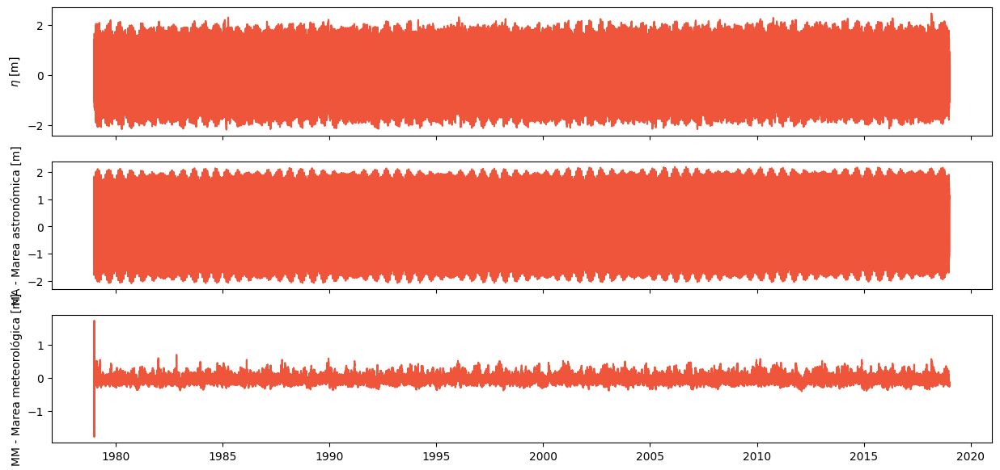

In [9]:
fig, axs = plt.subplots(3, sharex=True, figsize=(15, 7))
axs[0].plot(df.index, df['waterlevel'], c=colors[1])
axs[1].plot(df.index, df['waterlevel'] - df['surge'], c=colors[1])
axs[2].plot(df.index, df['surge'], c=colors[1])

axs[0].set_ylabel(r'$\eta$ [m]')
axs[1].set_ylabel('MA - Marea astronómica [m]')
axs[2].set_ylabel('MM - Marea meteorológica [m]')

# Para hacer zoom en un periodo concreto:
# axs[0].set_xlim([pd.Timestamp('2012-01-01'), pd.Timestamp('2013-01-31')])
plt.show()

### <span style='color:#1d6fa3'>3.2 Media mensual del nivel del mar</span>

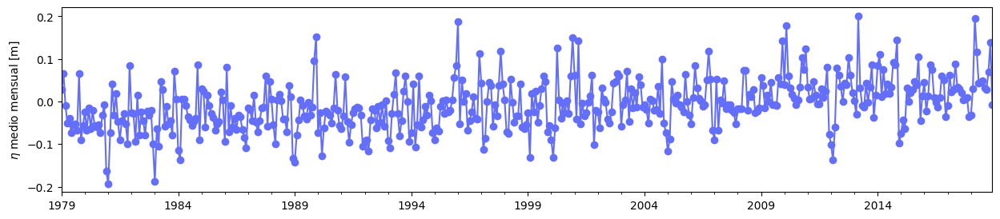

In [10]:
waterlevel_monthly = df['waterlevel'].resample('MS').mean()

plt.figure(figsize=(15, 3))
waterlevel_monthly.plot(marker='o', c=colors[0])
plt.ylabel(r'$\eta$ medio mensual [m]')
plt.xlabel('')
plt.show()

### <span style='color:#1d6fa3'>3.3 Oleaje: series temporales</span>

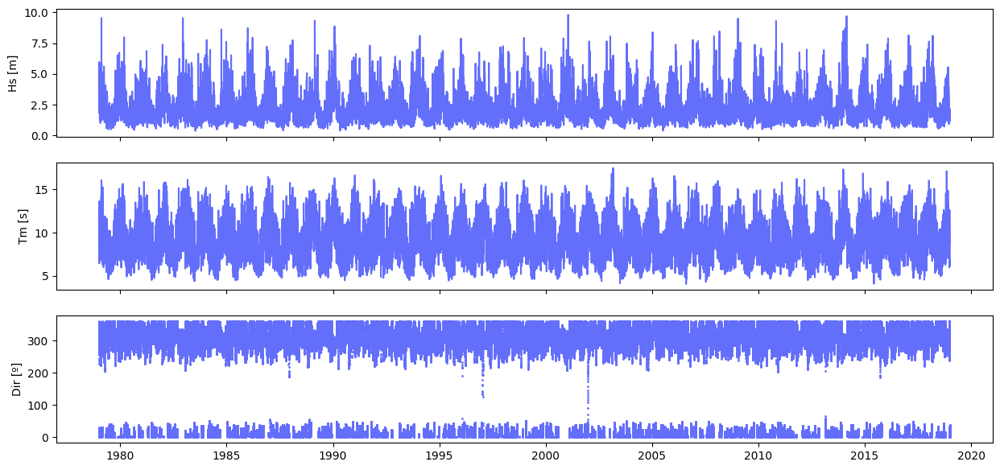

In [11]:
fig, axs = plt.subplots(3, sharex=True, figsize=(15, 7))
axs[0].plot(df.index, df['Hs'], c=colors[0])
axs[1].plot(df.index, df['Tm'], c=colors[0])
axs[2].scatter(df.index, df['Dir'], c=colors[0], s=1)

axs[0].set_ylabel('Hs [m]')
axs[1].set_ylabel('Tm [s]')
axs[2].set_ylabel('Dir [º]')
plt.show()

### <span style='color:#1d6fa3'>3.4 Relación entre variables del oleaje</span>

Calculamos un indicador de la energía del oleaje, $E \propto H_s^2\,T_m$, y lo usamos para colorear los puntos.

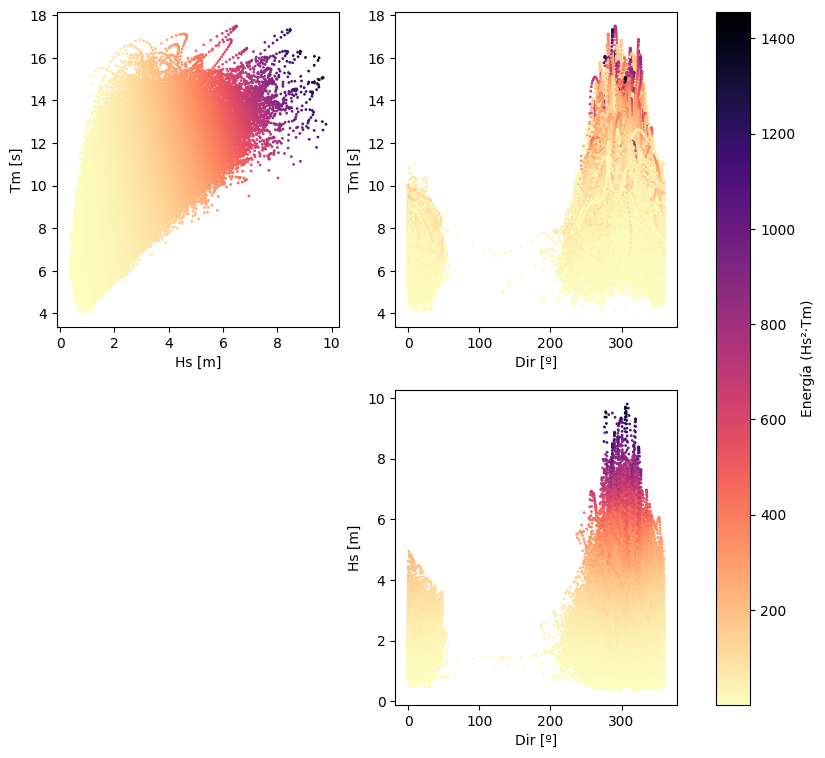

In [12]:
df['E'] = df['Hs']**2 * df['Tm']

fig, axs = plt.subplots(2, 2, figsize=(10, 9))
im = axs[0, 0].scatter(df['Hs'], df['Tm'], c=df['E'], cmap='magma_r', s=1)
axs[0, 1].scatter(df['Dir'], df['Tm'], c=df['E'], cmap='magma_r', s=1)
axs[1, 1].scatter(df['Dir'], df['Hs'], c=df['E'], cmap='magma_r', s=1)
axs[1, 0].axis('off')

axs[0, 0].set_xlabel('Hs [m]');  axs[0, 0].set_ylabel('Tm [s]')
axs[0, 1].set_xlabel('Dir [º]'); axs[0, 1].set_ylabel('Tm [s]')
axs[1, 1].set_xlabel('Dir [º]'); axs[1, 1].set_ylabel('Hs [m]')

fig.colorbar(im, ax=axs.ravel().tolist()).set_label('Energía (Hs²·Tm)')
plt.show()

### <span style='color:#1d6fa3'>3.5 Variabilidad mensual de la altura de ola</span>

INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


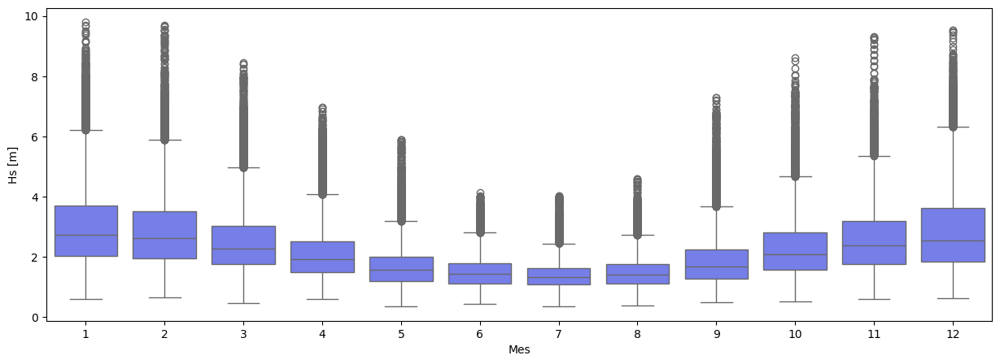

In [13]:
df['month'] = df.index.month

plt.figure(figsize=(15, 5))
sns.boxplot(x='month', y='Hs', data=df, color=colors[0])
plt.xlabel('Mes')
plt.ylabel('Hs [m]')
plt.show()

---

## 4. Propagación del oleaje con la ley de Snell

Para obtener el clima marítimo en la costa (*nearshore*) es necesario **propagar el oleaje** desde el punto offshore
hasta la profundidad de interés. Lo haremos aplicando la **ley de Snell** (oleaje monocromático) con
asomeramiento y refracción, primero hasta una profundidad objetivo y después hasta la profundidad de rotura.

<p align="center">
  <img src="../images/Image_3.png" width="600">&nbsp;&nbsp;<img src="../images/Image_4.png" width="200">
</p>

<sub><i>© Imágenes: <i>Coastal Dynamics</i> Open Textbook, J. Bosboom & M. Stive. ISBN 978-94-6366-370-0 (paperback), 978-94-6366-371-7 (e-book). DOI 10.5074/T.2021.001</i></sub>

Se necesitan **4 parámetros**:

| Parámetro | Descripción |
|---|---|
| `h0` | Profundidad offshore [m] |
| `h1` | Profundidad objetivo (nearshore) [m] |
| `m` | Pendiente de la playa [-] |
| `orientation` | Orientación de la playa [º] |

### <span style='color:#1d6fa3'>4.1 Profundidades offshore (h0) y objetivo (h1)</span>

<div style="background-color: #fff8e1; border-left: 6px solid #f7c61f; padding: 10px 16px; border-radius: 6px;">
<b>✏️ INPUTS</b> — modifica estos valores en la celda siguiente
<ul style="margin-bottom: 0;">
<li><code>h0</code>: profundidad offshore [m]</li>
<li><code>h1</code>: profundidad objetivo / nearshore [m]</li>
</ul>
</div>

In [14]:
h0 = 40  # profundidad offshore [m]
h1 = 20  # profundidad objetivo [m]

### <span style='color:#1d6fa3'>4.2 Pendiente (m) y orientación (orientation) de la playa</span>

Como referencia, podemos consultar la pendiente en la base de datos global de pendientes *nearshore*
([4TU.ResearchData](https://data.4tu.nl/articles/_/12712265/1)). Buscamos el punto más cercano a nuestra playa.

<div style="background-color: #fff8e1; border-left: 6px solid #f7c61f; padding: 10px 16px; border-radius: 6px;">
<b>✏️ INPUTS</b> — modifica estos valores en la celda siguiente
<ul style="margin-bottom: 0;">
<li><code>X, Y</code>: coordenadas (lon, lat) de la playa</li>
</ul>
</div>

In [15]:
X, Y = -8.89, 43.33  # coordenadas de la playa de Razo

global_slopes = pd.read_csv(op.join(DATA, 'nearshore_slopes.csv'))

# Punto de la base de datos más cercano (distancia euclídea)
distances = np.sqrt((global_slopes['X'] - X)**2 + (global_slopes['Y'] - Y)**2)
closest_position = global_slopes.loc[distances.idxmin()]

print(f'Punto de partida:    ({X}, {Y})')
print(f'Punto más cercano:   ({closest_position.X:.3f}, {closest_position.Y:.3f})')
print(f'Pendiente en ese punto: {closest_position.slope:.4f}')

Punto de partida:    (-8.89, 43.33)
Punto más cercano:   (-8.888, 43.319)
Pendiente en ese punto: 0.0334


<div style="background-color: #fff8e1; border-left: 6px solid #f7c61f; padding: 10px 16px; border-radius: 6px;">
<b>✏️ INPUTS</b> — modifica estos valores en la celda siguiente
<ul style="margin-bottom: 0;">
<li><code>m</code>: pendiente de la playa [-]</li>
<li><code>orientation</code>: ángulo entre el norte y la perpendicular a la playa, medido en sentido horario [º]</li>
</ul>
</div>

In [16]:
m = 20/920         # pendiente obtenida de Navionics
# m = 0.033        # pendiente obtenida de la base de datos global

orientation = 350  # orientación de la playa [º]

<p align="center">
  <img src="../images/Image_6.png" width="400">&nbsp;&nbsp;<img src="../images/Image_7.png" width="600">
</p>

### <span style='color:#1d6fa3'>4.3 Dirección relativa del oleaje (θ₀)</span>

Calculamos la dirección del oleaje relativa a la normal de la playa ($\theta_0$) a partir de la dirección offshore (`Dir`).

In [17]:
df_0 = theta_0(df, orientation)
df_0

,Hs,Tm,Dir,surge,waterlevel,latitude,longitude,station,E,month,theta_0
time,,,,,,,,,,,
1979-01-01 00:00:00,5.938938,12.171256,282.628185,1.090,0.018,43.400002,351.200012,3200,429.292139,1,67.371815
1979-01-01 01:00:00,5.918623,12.145249,283.452206,0.335,0.067,43.400002,351.200012,3200,425.449329,1,66.547794
1979-01-01 02:00:00,5.888867,12.091790,284.325668,-0.547,0.078,43.400002,351.200012,3200,419.328267,1,65.674332
1979-01-01 03:00:00,5.819055,12.055668,285.149689,-1.313,0.073,43.400002,351.200012,3200,408.221864,1,64.850311
1979-01-01 04:00:00,5.706612,12.043243,285.819893,-1.754,0.074,43.400002,351.200012,3200,392.193255,1,64.180107
...,...,...,...,...,...,...,...,...,...,...,...
2018-12-31 19:00:00,2.005709,6.387819,36.212972,-0.117,-0.489,43.400002,351.200012,3200,25.697365,12,46.212972
2018-12-31 20:00:00,1.997984,6.394176,36.971071,-0.122,-0.012,43.400002,351.200012,3200,25.525175,12,46.971071
2018-12-31 21:00:00,1.994837,6.393021,37.806079,-0.140,0.433,43.400002,351.200012,3200,25.440223,12,47.806079


### <span style='color:#1d6fa3'>4.4 Propagación hasta la profundidad objetivo (h1)</span>

In [18]:
df_1 = snell_mono_prop(df_0, h0, h1, m, orientation)
df_1

,Hs,Tm,Dir,surge,waterlevel,latitude,longitude,station,E,month,theta_0,H1,H1_Goda,L0,theta_1,Dir1
time,,,,,,,,,,,,,,,,
1979-01-01 00:00:00,5.938938,12.171256,282.628185,1.090,0.018,43.400002,351.200012,3200,429.292139,1,67.371815,4.593380,4.593380,231.291644,46.380901,303.619099
1979-01-01 01:00:00,5.918623,12.145249,283.452206,0.335,0.067,43.400002,351.200012,3200,425.449329,1,66.547794,4.638957,4.638957,230.304263,46.044298,303.955702
1979-01-01 02:00:00,5.888867,12.091790,284.325668,-0.547,0.078,43.400002,351.200012,3200,419.328267,1,65.674332,4.676170,4.676170,228.281279,45.704991,304.295009
1979-01-01 03:00:00,5.819055,12.055668,285.149689,-1.313,0.073,43.400002,351.200012,3200,408.221864,1,64.850311,4.675390,4.675390,226.919449,45.358436,304.641564
1979-01-01 04:00:00,5.706612,12.043243,285.819893,-1.754,0.074,43.400002,351.200012,3200,392.193255,1,64.180107,4.627879,4.627879,226.451922,45.050460,304.949540
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2018-12-31 19:00:00,2.005709,6.387819,36.212972,-0.117,-0.489,43.400002,351.200012,3200,25.697365,12,46.212972,1.885170,1.885170,63.708056,44.302393,34.302393
2018-12-31 20:00:00,1.997984,6.394176,36.971071,-0.122,-0.012,43.400002,351.200012,3200,25.525175,12,46.971071,1.875711,1.875711,63.834927,44.997768,34.997768
2018-12-31 21:00:00,1.994837,6.393021,37.806079,-0.140,0.433,43.400002,351.200012,3200,25.440223,12,47.806079,1.870920,1.870920,63.811850,45.778821,35.778821


### <span style='color:#1d6fa3'>4.5 Propagación hasta la profundidad de rotura (hb)</span>

Eliminamos los estados de mar sin oleaje y aquellos con incidencia muy oblicua ($\theta_1 > 45º$).
Después calculamos la **profundidad de rotura** $h_b$: el punto en el que la altura de ola propagada con Snell desde $h_1$
alcanza la altura de rotura del criterio elegido, $H(h_b) = H_b(h_b)$, y propagamos hasta ella.

| Criterio | Altura de rotura |
|---|---|
| `'McCowan'` | $H_b = 0.78\,h$ |
| `'Miche'` | $H_b = 0.142\,L\tanh(kh)$ |
| `'Goda'` | $H_b = 0.17\,L_0\left[1-\exp\left(-1.5\pi\dfrac{h}{L_0}(1+15m^{4/3})\right)\right]$ |
| `'Weggel'` | $\dfrac{H_b}{h_b} = b - a\dfrac{H_b}{gT^2}$, $\; a = 43.8(1-e^{-19m})$, $\; b = \dfrac{1.56}{1+e^{-19.5m}}$ |

<div style="background-color: #fff8e1; border-left: 6px solid #f7c61f; padding: 10px 16px; border-radius: 6px;">
<b>✏️ INPUTS</b> — modifica estos valores en la celda siguiente
<ul style="margin-bottom: 0;">
<li><code>criterio_rotura</code>: criterio de rotura: 'McCowan', 'Miche', 'Goda' o 'Weggel'</li>
</ul>
</div>

In [19]:
criterio_rotura = 'Goda'

In [20]:
df_1 = df_1[df_1['H1_Goda'] != 0]   # eliminamos Hs = 0
df_1 = df_1[df_1['theta_1'] <= 45].copy()  # nos quedamos con theta_1 <= 45º

# Profundidad de rotura
df_1['hb'] = hb_calculation_vec(df_1['H1_Goda'], df_1['Tm'], df_1['theta_1'], h1, m, criterio=criterio_rotura)
df_1 = df_1.dropna(subset=['H1_Goda', 'Tm', 'Dir1', 'theta_1', 'hb'], how='any')

In [21]:
# Altura, ángulo y dirección del oleaje en rotura (Hb, thetab, Dirb)
df_1 = snell_mono_prop_breaking(df_1, h1, m, orientation)
df_1

,Hs,Tm,Dir,surge,waterlevel,latitude,longitude,station,E,month,theta_0,H1,H1_Goda,L0,theta_1,Dir1,hb,Hb,thetab,Dirb
time,,,,,,,,,,,,,,,,,,,,
1979-01-01 05:00:00,5.566415,12.040353,286.352760,-1.782,0.053,43.400002,351.200012,3200,373.070102,1,63.647240,4.546802,4.546802,226.343264,44.793454,305.206546,6.006752,4.907576,24.445055,325.554945
1979-01-01 06:00:00,5.413344,12.032840,286.742796,-1.374,0.033,43.400002,351.200012,3200,352.613823,1,63.257204,4.444187,4.444187,226.060874,44.608811,305.391189,5.889319,4.817515,24.122587,325.877413
1979-01-01 07:00:00,5.251402,12.028216,287.000989,-0.641,0.007,43.400002,351.200012,3200,331.704847,1,62.999011,4.325422,4.325422,225.887184,44.485066,305.514934,5.750064,4.710662,23.780639,326.219361
1979-01-01 08:00:00,5.082308,12.038330,287.132833,0.265,-0.006,43.400002,351.200012,3200,310.948338,1,62.867167,4.193724,4.193724,226.267218,44.408024,305.591976,5.593898,4.591182,23.417232,326.582768
1979-01-01 09:00:00,4.913500,12.053935,287.149313,1.071,-0.049,43.400002,351.200012,3200,291.011910,1,62.850687,4.056051,4.056051,226.854184,44.382929,305.617071,5.428955,4.464686,23.052608,326.947392
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2018-12-31 16:00:00,2.018871,6.315288,33.592586,-0.175,-1.082,43.400002,351.200012,3200,25.740094,12,43.592586,1.908517,1.908517,62.269506,41.976363,31.976363,2.394008,1.898581,18.990395,8.990395
2018-12-31 17:00:00,2.030315,6.321356,34.806643,-0.141,-1.090,43.400002,351.200012,3200,26.057768,12,44.806643,1.916680,1.916680,62.389233,43.111022,33.111022,2.386881,1.893814,19.380254,9.380254
2018-12-31 18:00:00,2.024593,6.347074,35.718560,-0.130,-0.884,43.400002,351.200012,3200,26.016509,12,45.718560,1.907377,1.907377,62.897924,43.919860,33.919860,2.366365,1.880506,19.544950,9.544950


---

## 5. Comparación offshore – nearshore

Comparamos el oleaje en los tres puntos:

| Punto | Altura | Dirección |
|---|---|---|
| **Offshore** (h0) | `Hs` | `Dir` |
| **Nearshore** – profundidad objetivo (h1) | `H1_Goda` | `Dir1` |
| **Nearshore** – profundidad de rotura (hb) | `Hb` | `Dirb` |

In [22]:
casos = [
    ('Offshore',                          'Hs',        'Dir'),
    ('Nearshore (profundidad objetivo)',  'H1_Goda',   'Dir1'),
    ('Nearshore (profundidad de rotura)', 'Hb', 'Dirb'),
]

### <span style='color:#1d6fa3'>5.1 Series temporales</span>

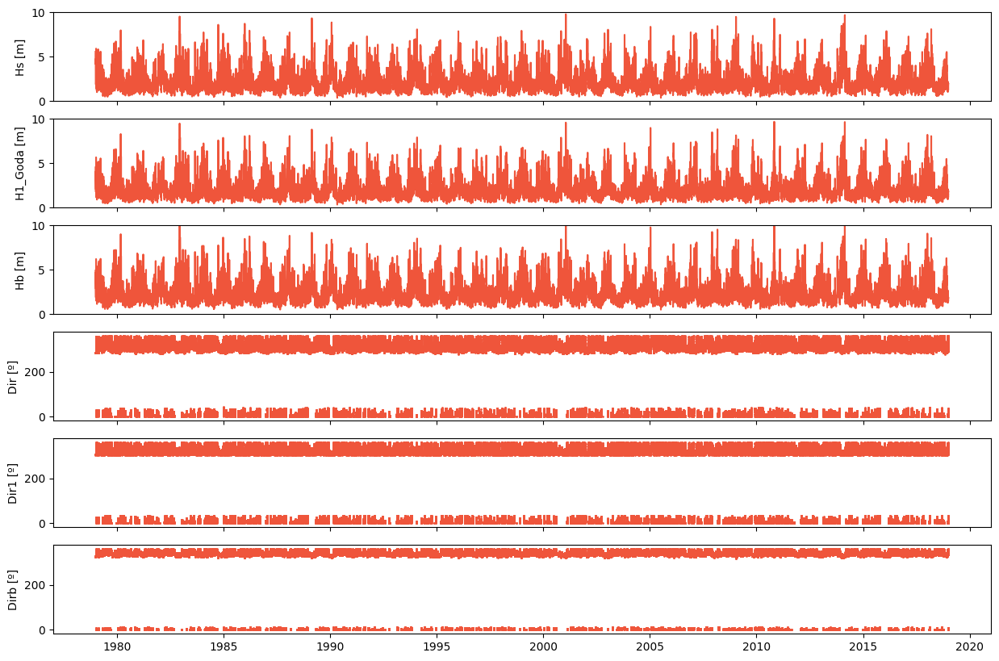

In [23]:
fig, axs = plt.subplots(6, sharex=True, figsize=(15, 10))
for i, (nombre, H, D) in enumerate(casos):
    axs[i].plot(df_1.index, df_1[H], c=colors[1])
    axs[i].set_ylabel(f'{H} [m]')
    axs[i].set_ylim(0, 10)
    axs[i + 3].scatter(df_1.index, df_1[D], c=colors[1], s=1)
    axs[i + 3].set_ylabel(f'{D} [º]')
plt.show()

### <span style='color:#1d6fa3'>5.2 Histogramas de altura de ola</span>

In [24]:
for nombre, H, _ in casos:
    fig = make_subplots(rows=1, cols=2, subplot_titles=['Frecuencia', 'Densidad de probabilidad'])
    fig.add_trace(go.Histogram(x=df_1[H], nbinsx=30), 1, 1)
    fig.add_trace(go.Histogram(x=df_1[H], nbinsx=30, histnorm='probability density'), 1, 2)
    fig.update_layout(
        title={'text': nombre, 'x': 0.5, 'xanchor': 'center', 'font': {'size': 22}},
        showlegend=False, height=450, width=1100,
    )
    fig.update_xaxes(range=[0, 6.75], title_text=f'{H} [m]')
    fig.update_yaxes(range=[0, 90000], row=1, col=1)
    fig.update_yaxes(range=[0, 1], row=1, col=2)
    fig.show()

### <span style='color:#1d6fa3'>5.3 Rosas de oleaje</span>

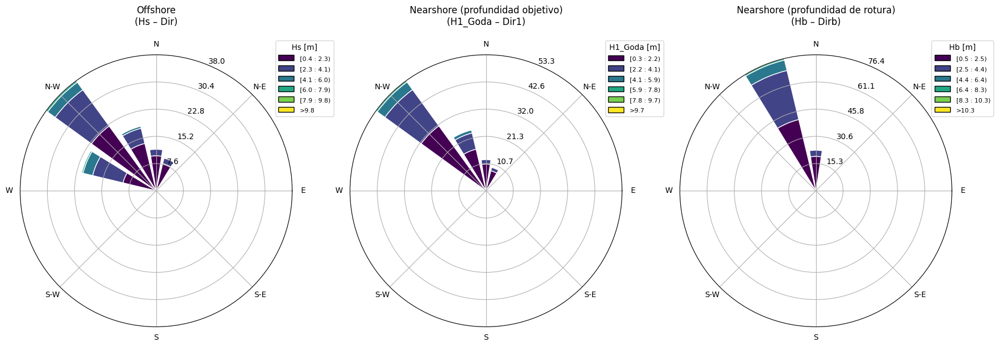

In [25]:
fig = plt.figure(figsize=(18, 6))
for i, (nombre, H, D) in enumerate(casos):
    ax = fig.add_subplot(1, 3, i + 1, projection='windrose')
    ax.bar(df_1[D], df_1[H], normed=True, opening=0.8, edgecolor='white', nsector=16)
    ax.set_legend(loc='upper right', bbox_to_anchor=(1.15, 1.05), title=f'{H} [m]')
    ax.set_title(f'{nombre}\n({H} – {D})', pad=20)
plt.tight_layout()
plt.show()

### <span style='color:#1d6fa3'>5.4 Diagramas polares Hs – Dir – Tm</span>

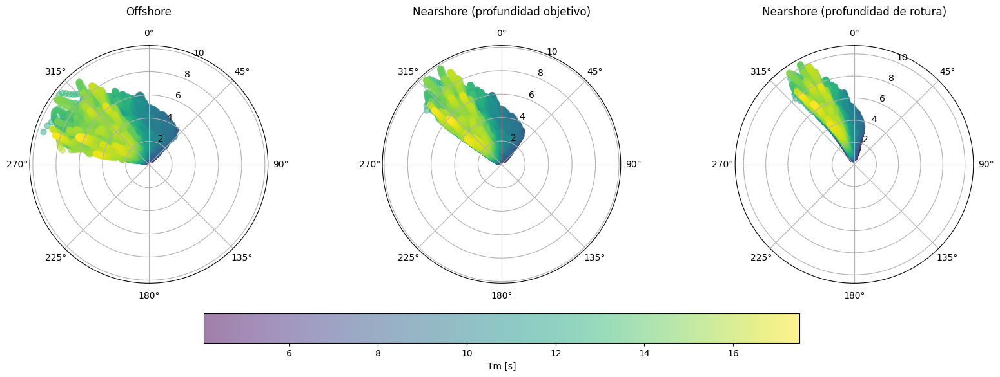

In [26]:
df_sorted = df_1.sort_values(by='Tm')

fig = plt.figure(figsize=[20, 6])
axs = []
for i, (nombre, H, D) in enumerate(casos):
    ax = fig.add_subplot(1, 3, i + 1, projection='polar')
    sc = ax.scatter(np.deg2rad(df_sorted[D]), df_sorted[H], c=df_sorted['Tm'], s=40, cmap='viridis', alpha=0.5)
    ax.set_title(nombre, pad=15)
    ax.set_theta_zero_location('N')
    ax.set_theta_direction(-1)
    axs.append(ax)

fig.colorbar(sc, ax=axs, pad=0.1, orientation='horizontal', fraction=.1).set_label('Tm [s]')
plt.show()

### <span style='color:#1d6fa3'>5.5 Distribución conjunta Hs – Tm</span>

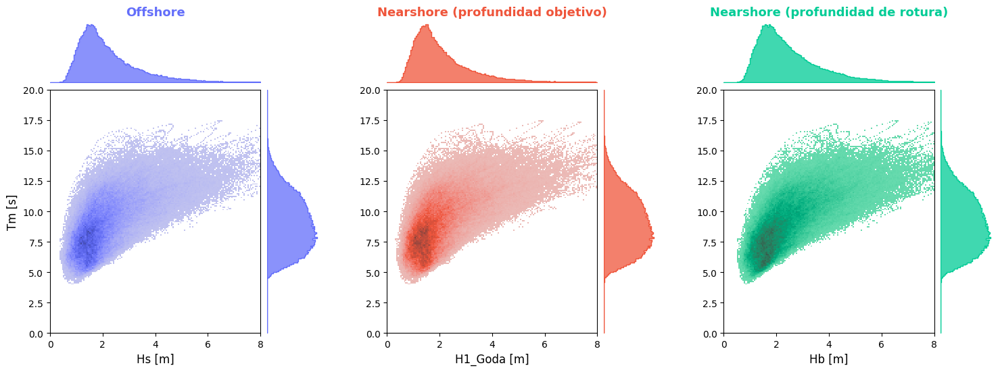

In [27]:
colores_casos = [colors[0], colors[1], colors[2]]  # un color por profundidad
bins_H = np.arange(0, 8.05, 0.05)
bins_T = np.arange(0, 20.1, 0.1)


def ejes_conjunta(fig, celda):
    """Crea un panel con histograma 2D central y marginales arriba y a la derecha."""
    gs = celda.subgridspec(2, 2, width_ratios=[4, 1], height_ratios=[1, 4], wspace=0.05, hspace=0.05)
    ax = fig.add_subplot(gs[1, 0])
    ax_x = fig.add_subplot(gs[0, 0], sharex=ax)
    ax_y = fig.add_subplot(gs[1, 1], sharey=ax)
    ax_x.axis('off')
    ax_y.axis('off')
    ax.set_xlim(0, 8)
    ax.set_ylim(0, 20)
    return ax, ax_x, ax_y


fig = plt.figure(figsize=(18, 6))
celdas = fig.add_gridspec(1, 3, wspace=0.25)

for k, ((nombre, H, _), col) in enumerate(zip(casos, colores_casos)):
    ax, ax_x, ax_y = ejes_conjunta(fig, celdas[k])
    sns.histplot(x=df_1[H], y=df_1['Tm'], bins=[bins_H, bins_T], color=col, ax=ax)
    sns.histplot(x=df_1[H], bins=bins_H, color=col, element='step', ax=ax_x)
    sns.histplot(y=df_1['Tm'], bins=bins_T, color=col, element='step', ax=ax_y)
    ax.set_xlabel(f'{H} [m]', fontsize=12)
    ax.set_ylabel('Tm [s]' if k == 0 else '', fontsize=12)
    ax_x.set_title(nombre, fontsize=13, color=col, fontweight='bold')

plt.show()


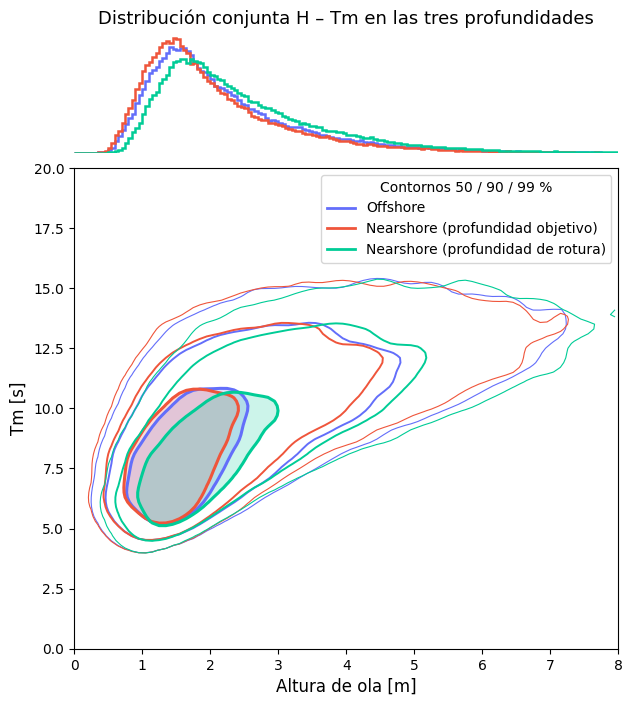

In [28]:
from scipy.ndimage import gaussian_filter

# Las tres distribuciones superpuestas: contornos que encierran el 50 %, 90 % y 99 % de los datos
# (Tm no cambia al propagar, así que solo se muestra el marginal de altura de ola)
fig = plt.figure(figsize=(9, 8))
ax, ax_x, ax_y = ejes_conjunta(fig, fig.add_gridspec(1, 1)[0])
ax_y.set_visible(False)

bins_Hc = np.arange(0, 8.1, 0.1)
bins_Tc = np.arange(0, 20.2, 0.2)
centros_H = 0.5 * (bins_Hc[1:] + bins_Hc[:-1])
centros_T = 0.5 * (bins_Tc[1:] + bins_Tc[:-1])
fracciones = [0.99, 0.9, 0.5]

for (nombre, H, _), col in zip(casos, colores_casos):
    dens, _, _ = np.histogram2d(df_1[H], df_1['Tm'], bins=[bins_Hc, bins_Tc])
    dens = gaussian_filter(dens, sigma=1.5)
    dens = dens / dens.sum()

    # Nivel de densidad que encierra cada fracción de los datos
    orden = np.sort(dens.ravel())[::-1]
    acumulada = np.cumsum(orden)
    niveles = [orden[np.searchsorted(acumulada, f)] for f in fracciones]

    ax.contourf(centros_H, centros_T, dens.T, levels=[niveles[2], dens.max()], colors=[col], alpha=0.2)
    ax.contour(centros_H, centros_T, dens.T, levels=niveles, colors=[col], linewidths=[0.8, 1.4, 2.2])
    ax.plot([], [], color=col, lw=2, label=nombre)

    ax_x.hist(df_1[H], bins=bins_H, density=True, histtype='step', color=col, lw=1.8)

ax.set_xlabel('Altura de ola [m]', fontsize=12)
ax.set_ylabel('Tm [s]', fontsize=12)
ax.legend(loc='upper right', title='Contornos 50 / 90 / 99 %')
ax_x.set_title('Distribución conjunta H – Tm en las tres profundidades', fontsize=13)
plt.show()


---

## 6. Flujo medio de energía del oleaje

El flujo de energía del oleaje en rotura (por unidad de anchura del frente de onda) es la energía por unidad
de superficie multiplicada por la celeridad de grupo **en la profundidad de rotura**:

$$ F_b = E_b\,C_{g,b} = \frac{1}{8}\,\rho\, g\, H_b^2 \; C_g(h_b, T_m) \quad [\mathrm{kW/m}] $$

donde $C_g(h_b, T_m)$ se calcula con la ecuación de la dispersión (en rotura, aguas someras, $C_{g,b} \approx \sqrt{g\,h_b}$).
La dirección media del flujo se obtiene a partir de la suma vectorial de sus componentes.

<div style="background-color: #fff8e1; border-left: 6px solid #f7c61f; padding: 10px 16px; border-radius: 6px;">
<b>✏️ INPUTS</b> — modifica estos valores en la celda siguiente
<ul style="margin-bottom: 0;">
<li><code>densidad</code>: densidad del agua de mar [kg/m³] (por defecto 1025)</li>
<li><code>g</code>: aceleración de la gravedad [m/s²] (por defecto 9.81)</li>
</ul>
</div>

In [29]:
densidad = 1025  # kg/m3
g = 9.81         # m/s2

### <span style='color:#1d6fa3'>6.1 Flujo medio de energía de toda la serie</span>

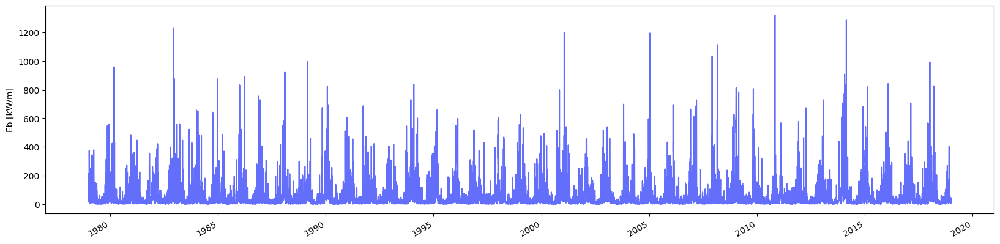

In [30]:
# Celeridad de grupo en la profundidad de rotura
L_b = waves_dispersion(df_1['Tm'].values, df_1['hb'].values)[0]
df_1['Cgb'] = cg(L_b, df_1['Tm'].values, df_1['hb'].values)

# Flujo de energía en rotura [kW/m]
df_1['Eb'] = densidad * g * df_1['Hb']**2 / 8 * df_1['Cgb'] / 1000

# Componentes del flujo
df_1['Dirb_rad'] = np.radians(df_1['Dirb'])
df_1['Few'] = df_1['Eb'] * np.cos(df_1['Dirb_rad'])
df_1['Fns'] = df_1['Eb'] * np.sin(df_1['Dirb_rad'])

df_1['Eb'].plot(figsize=[20, 5], c=colors[0])
plt.ylabel('Eb [kW/m]')
plt.xlabel('')
plt.show()

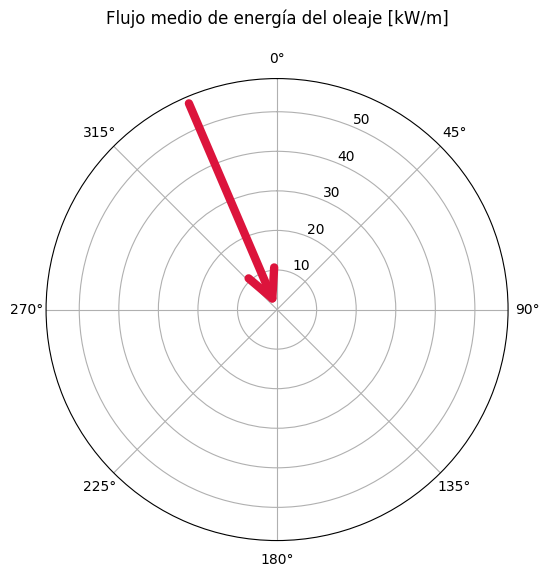

Flujo medio de energía:                 57.39 kW/m
Dirección del flujo medio respecto al N: 156.85 º


In [31]:
# Dirección y módulo del flujo medio
Flux_dir = np.degrees(np.arctan2(df_1['Fns'].sum(), df_1['Few'].sum()))
Flux_mean = df_1['Eb'].mean()

# Cambiamos la dirección para pintar
if Flux_dir < 0:
    Flux_dir = Flux_dir + 180

fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(111, polar=True)
ax.annotate('', xy=(0, 0), xytext=(np.radians(Flux_dir - 180), Flux_mean),
            arrowprops=dict(arrowstyle='->', linewidth=6, color='crimson', mutation_scale=50))
ax.set_theta_zero_location('N')
ax.set_theta_direction(-1)
ax.set_rlim(0, Flux_mean + 1)
ax.set_title('Flujo medio de energía del oleaje [kW/m]', pad=20)
plt.show()

print(f'Flujo medio de energía:                 {Flux_mean:.2f} kW/m')
print(f'Dirección del flujo medio respecto al N: {Flux_dir:.2f} º')

### <span style='color:#1d6fa3'>6.2 Flujo medio de energía anual</span>

In [32]:
df_1_years = df_1.resample('YS').mean(numeric_only=True)
df_1_years['Flux_Direction'] = np.degrees(np.arctan2(df_1_years['Fns'], df_1_years['Few']))
years = df_1_years.index.year

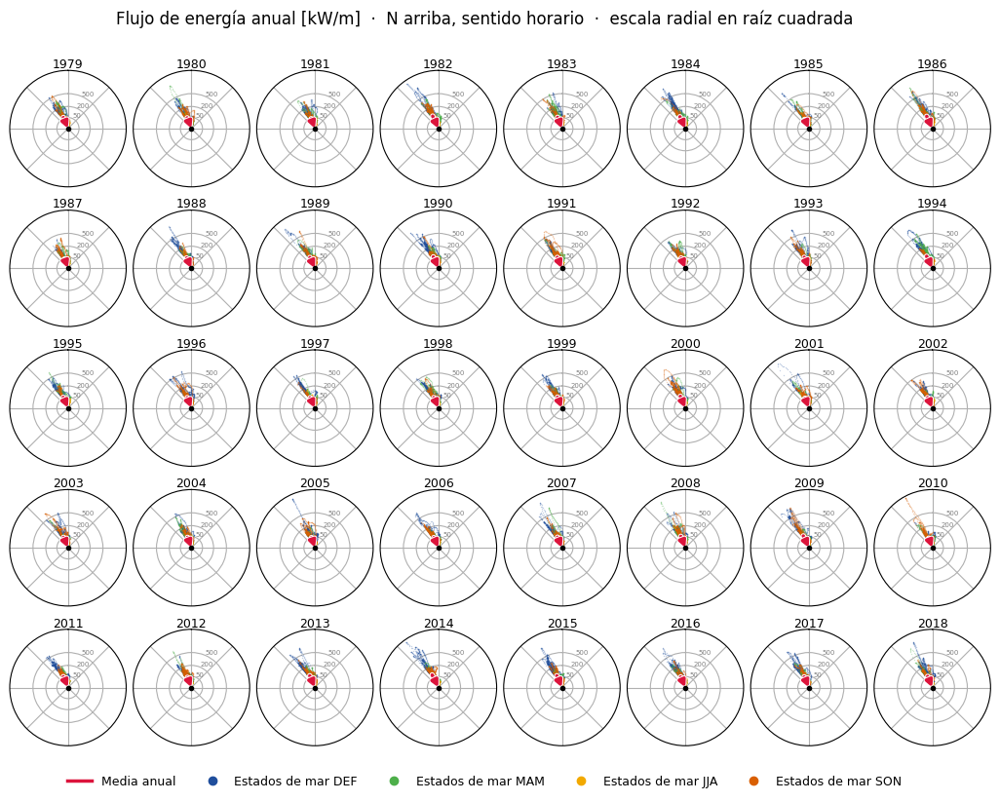

In [33]:
# Todos los estados de mar de cada año (puntos, coloreados por estación) + flujo medio anual (flecha)
import matplotlib.patheffects as pe

estaciones = {'DEF': [12, 1, 2], 'MAM': [3, 4, 5], 'JJA': [6, 7, 8], 'SON': [9, 10, 11]}
color_estacion = {'DEF': '#1f4e9c', 'MAM': '#4daf4a', 'JJA': '#f2a900', 'SON': '#d95f02'}

n = len(df_1_years)
ncols = 8
nrows = int(np.ceil(n / ncols))
fig, axs = plt.subplots(nrows, ncols, figsize=(13, 1.8 * nrows), subplot_kw=dict(polar=True),
                        gridspec_kw=dict(wspace=0.05, hspace=0.2))
axs = np.atleast_1d(axs).flatten()
rmax = df_1['Eb'].max() * 1.05

for i, etiqueta in enumerate(years):
    ax = axs[i]
    datos = df_1[df_1.index.year == etiqueta]
    for est, lista in estaciones.items():
        sel = datos[datos.index.month.isin(lista)]
        ax.scatter(np.radians(sel['Dirb']), sel['Eb'], s=1, color=color_estacion[est],
                   alpha=0.25, linewidths=0, rasterized=True, zorder=2)
    ax.annotate('', xy=(0, 0),
                xytext=(np.radians(df_1_years['Flux_Direction'].iloc[i]), df_1_years['Eb'].iloc[i]),
                arrowprops=dict(arrowstyle='-|>', linewidth=2.5, color='crimson', mutation_scale=10,
                                shrinkA=0, shrinkB=0, path_effects=[pe.withStroke(linewidth=4, foreground='white')]),
                zorder=3)
    ax.plot(0, 0, marker='o', markersize=3, color='black', zorder=4)
    ax.set_theta_zero_location('N')
    ax.set_theta_direction(-1)
    # Escala radial en raíz cuadrada para que se vean a la vez la media y los temporales
    ax.set_rscale('function', functions=(np.sqrt, np.square))
    ax.set_rlim(0, rmax)
    ax.set_xticks(np.radians(np.arange(0, 360, 45)), [])
    ax.set_yticks([50, 200, 500])
    ax.tick_params(axis='y', labelsize=5, colors='grey')
    ax.set_title(str(etiqueta), fontsize=9, pad=2)

for ax in axs[n:]:
    ax.set_visible(False)

leyenda = [plt.Line2D([], [], color='crimson', lw=2.5, label='Media anual')]
leyenda += [plt.Line2D([], [], marker='o', ls='', color=c, label=f'Estados de mar {e}') for e, c in color_estacion.items()]
fig.legend(handles=leyenda, loc='lower center', ncol=5, frameon=False, fontsize=9, bbox_to_anchor=(0.5, 0.05))
fig.suptitle('Flujo de energía anual [kW/m]  ·  N arriba, sentido horario  ·  escala radial en raíz cuadrada',
             fontsize=12, y=0.95)
plt.show()


In [34]:
resumen = pd.DataFrame({
    'Año': list(years),
    'Flujo medio [kW/m]': df_1_years['Eb'].round(2).values,
    'Dirección [º]': df_1_years['Flux_Direction'].round(2).values,
}).set_index('Año')
resumen

,Flujo medio [kW/m],Dirección [º]
Año,,
1979,58.80,-22.56
1980,54.75,-21.66
1981,45.36,-20.68
1982,77.14,-24.59
1983,59.58,-20.97
1984,69.42,-24.62
1985,41.47,-23.66
1986,74.62,-24.59
1987,40.24,-20.00


### <span style='color:#1d6fa3'>6.3 Flujo medio de energía mensual</span>

In [35]:
df_1_months = df_1.groupby('month').mean(numeric_only=True)
df_1_months['Flux_Direction'] = np.degrees(np.arctan2(df_1_months['Fns'], df_1_months['Few']))
months = [calendar.month_name[i] for i in df_1_months.index]

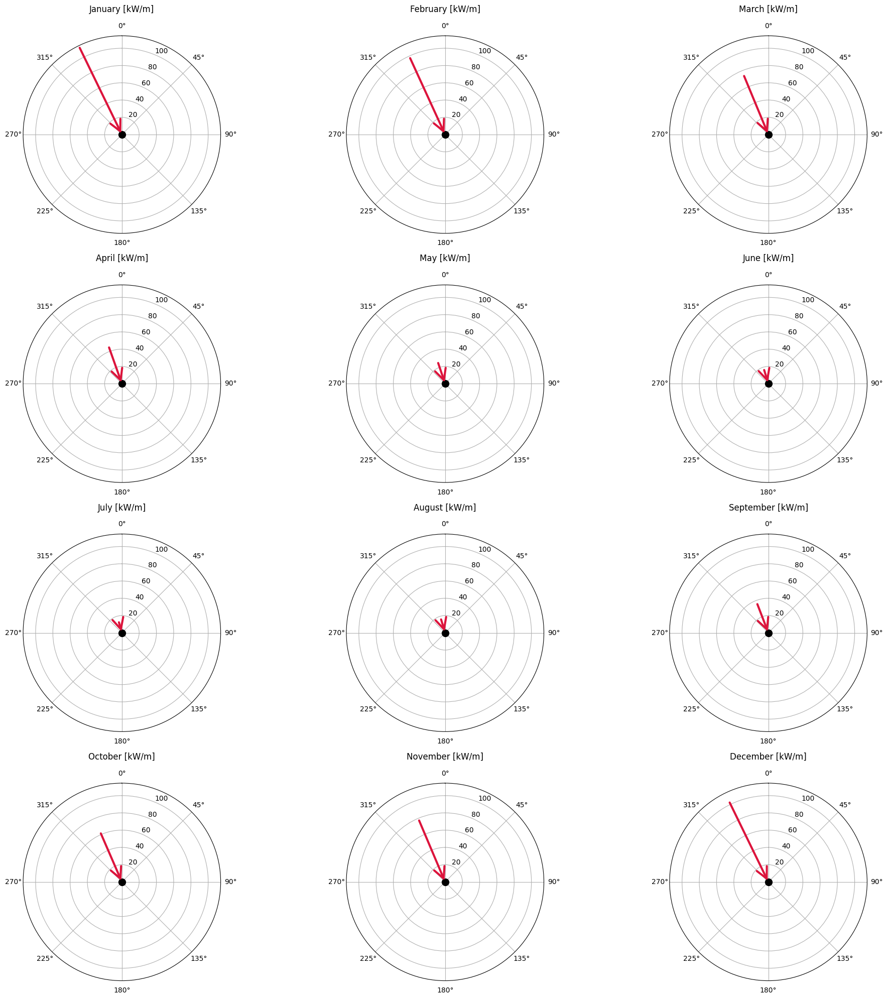

In [36]:
n = len(df_1_months)
nrows = int(np.ceil(n / 3))
fig, axs = plt.subplots(nrows, 3, figsize=(20, 5 * nrows), subplot_kw=dict(polar=True))
axs = np.atleast_1d(axs).flatten()

for i, etiqueta in enumerate(months):
    ax = axs[i]
    ax.plot(0, 0, marker='o', markersize=10, color='black')
    ax.annotate('', xy=(0, 0),
                xytext=(np.radians(df_1_months['Flux_Direction'].iloc[i]), df_1_months['Eb'].iloc[i]),
                arrowprops=dict(arrowstyle='->', linewidth=3, color='crimson', mutation_scale=40))
    ax.set_theta_zero_location('N')
    ax.set_theta_direction(-1)
    ax.set_rlim(0, df_1_months['Eb'].max() + 1)
    ax.set_title(f'{etiqueta} [kW/m]', pad=15)

for ax in axs[n:]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

In [37]:
resumen = pd.DataFrame({
    'Mes': list(months),
    'Flujo medio [kW/m]': df_1_months['Eb'].round(2).values,
    'Dirección [º]': df_1_months['Flux_Direction'].round(2).values,
}).set_index('Mes')
resumen

,Flujo medio [kW/m],Dirección [º]
Mes,,
January,113.45,-25.94
February,99.01,-24.60
March,75.09,-22.51
April,46.16,-19.53
May,26.92,-18.59
June,18.21,-17.04
July,14.31,-15.74
August,17.83,-16.84
September,37.21,-20.99


### <span style='color:#1d6fa3'>6.4 Flujo medio de energía estacional</span>

In [38]:
seasons_dict = {12: 'DEF', 1: 'DEF', 2: 'DEF',
                3: 'MAM', 4: 'MAM', 5: 'MAM',
                6: 'JJA', 7: 'JJA', 8: 'JJA',
                9: 'SON', 10: 'SON', 11: 'SON'}
df_1['Season'] = df_1['month'].map(seasons_dict)

seasonal_mean = df_1.groupby('Season').mean(numeric_only=True).reindex(['DEF', 'MAM', 'JJA', 'SON'])
seasonal_mean['Flux_Direction'] = np.degrees(np.arctan2(seasonal_mean['Fns'], seasonal_mean['Few']))
seasons = seasonal_mean.index

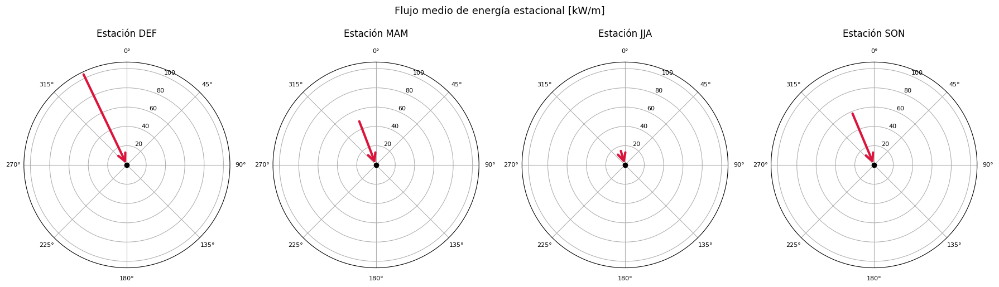

In [39]:
n = len(seasonal_mean)
fig, axs = plt.subplots(1, n, figsize=(4.5 * n, 5), subplot_kw=dict(polar=True))
axs = np.atleast_1d(axs).flatten()

for i, etiqueta in enumerate(seasons):
    ax = axs[i]
    ax.plot(0, 0, marker='o', markersize=6, color='black')
    ax.annotate('', xy=(0, 0),
                xytext=(np.radians(seasonal_mean['Flux_Direction'].iloc[i]), seasonal_mean['Eb'].iloc[i]),
                arrowprops=dict(arrowstyle='->', linewidth=3, color='crimson', mutation_scale=25))
    ax.set_theta_zero_location('N')
    ax.set_theta_direction(-1)
    ax.set_rlim(0, seasonal_mean['Eb'].max() + 1)
    ax.set_title(f'Estación {etiqueta}', pad=15)
    ax.tick_params(axis='both', labelsize=8)

fig.suptitle('Flujo medio de energía estacional [kW/m]', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

In [40]:
resumen = pd.DataFrame({
    'Estación': list(seasons),
    'Flujo medio [kW/m]': seasonal_mean['Eb'].round(2).values,
    'Dirección [º]': seasonal_mean['Flux_Direction'].round(2).values,
}).set_index('Estación')
resumen

,Flujo medio [kW/m],Dirección [º]
Estación,,
DEF,105.70,-25.55
MAM,50.01,-20.91
JJA,16.74,-16.59
SON,59.44,-22.72
